## **Portfolio Opdracht 2: Voorspel Verhuuraantallen**


##### Competitie: Predicting bike rental quantities | Kaggle
##### Teamnaam: Groep 4
##### Teamleden & Kaggle Usernames: 
+ Kaman - [Kaggle Username: KMT250]
+ Alex - [Kaggle Username: Alex Gaiser 2]
+ Pablo - [Kaggle Username: Artheriax]


### **Inleiding**

##### In dit project werken we als junior data scientists bij *CitiBike*. Het doel is om een machine learning model te ontwikkelen dat op basis van historische gegevens over het gebruik van de fietsverhuurservice kan verspellen hoeveel fietsen er per uur zullen worden verhuurd, zodat het bedrijf zijn fietsen efficienter kan verdelen en zodat klanten zo vaak mogelijk een fiets beschikbaar hebben wanneer zij die nodig hebben. 

##### **Opbouw van dit notebook**

+ **1. Data en exploratieve data-analyse (EDA)** - Opdracht 1
+ **2. Data opschonen en voorbereiden**
+ **3. Time series feature engineering** - Opdracht 2 (trend, Fourier, cycli, overige tijdsfeatures)
+ **4. Invloed van de features op de voorspellingen** - ablatietest met time-series cross-validatie
+ **5. Submissions voor de Kaggle-competitie** - per model een submissionbestand
+ **6. Conclusie Opdracht 1 en 2**


## 1. **Data en exploratieve data-analyse (EDA)**


### 1.1 **Uitleg van de kolommen**


##### De dataset bevat al numerieke waarden en dummyvariabelen. De kolommen betekenen: 
+ 'cnt' (target kolom): informatie over het aantal stuks dat per uur is verhuurd 
+ date_hour: informatie over de periode van 1-1-2011 t/m 30-11-2012
+ holiday: Vakantiedag of geen vakantiedag 
+ weathersit: Weersituatie - 
1. Helder, licht bewolkt, deels bewolkt
2. Mistig, mistig en licht bewolkt
3. Lichte sneeuw, lichte regen, lichte regen en onweer, zwaar bewolkt, lichte regen en zwaar bewolkt
4. Zware regen, hagel, zware mist, sneeuw 
+ temp: genormaliseerde temperatuur
+ atemp: genormaliseerde gevoelstemperatuur 
+ hum: genormaliseerde luchtvochtigheid 
+ windspeed: genormaliseerde windsnelheid 


In [43]:
# pylint: disable=invalid-name
""" Portfolio Opdracht 2 (Groep 4): tijdreeksfeatures voor de CitiBike-verhuurdata.

De notebook bouwt voort op de EDA uit Opdracht 1. De bestandsnaam ligt vast door de
opdracht en namen als X_train en y_train zijn standaard in ML-notebooks; daarom staat
invalid-name hierboven uit.
"""

# Python libraries importeren

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf


In [44]:
def converteer_bool_kolommen(df: pd.DataFrame) -> pd.DataFrame:
    """ Zet bool-kolommen om naar 0/1 (nodig voor sommige sklearn- / XGBoost-versies)."""
    for kolom in df.select_dtypes(include="bool").columns:
        df[kolom] = df[kolom].astype(int)
    return df


class DataLoader:
    """ Laadt de ruwe train- en testdataset in voor de EDA."""

    def __init__(self, train_path: str, test_path: str):
        self.train_path = train_path
        self.test_path = test_path
        # Worden gevuld door load_data(); hier vast initialiseren zodat het objectcontract klopt.
        self.train_df = pd.DataFrame()
        self.test_df = pd.DataFrame()

    def load_data(self) -> tuple[pd.DataFrame, pd.DataFrame]:
        """ Leest beide CSV-bestanden in en converteert booleans naar 0/1."""
        self.train_df = converteer_bool_kolommen(pd.read_csv(self.train_path))
        self.test_df = converteer_bool_kolommen(pd.read_csv(self.test_path))
        return self.train_df, self.test_df

    def convert_datetime(self, df: pd.DataFrame, col: str = "date_hour") -> pd.DataFrame:
        """ Zet een kolom met tijdstempel-strings om in een correct pandas-datetime-object."""
        df = df.copy()
        df[col] = pd.to_datetime(df[col])
        df = df.sort_values(by=col).reset_index(drop=True)
        return df


class TimeFeatureEngineer:  # pylint: disable=too-few-public-methods
    """ Extraheert kalender- en tijdgerelateerde kenmerken uit een datum-tijd-kolom."""

    def __init__(self, datetime_col: str = "date_hour"):
        self.datetime_col = datetime_col

    def extract_calendar_features(self, df: pd.DataFrame) -> pd.DataFrame:
        """ Extraheert uur, dag van de week, maand, jaar en "is_weekend"."""
        df = df.copy()
        dt = df[self.datetime_col].dt

        df["hour"] = dt.hour
        df["day_of_week"] = dt.day_of_week
        df["month"] = dt.month
        df["year"] = dt.year
        df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)
        return df


class EDAAnalyzer:
    """ Voert een gestructureerde verkennende data-analyse uit voor tijdreeksregressie."""

    def __init__(self, datetime_col: str = "date_hour", target_col: str = "cnt"):
        self.datetime_col = datetime_col
        self.target_col = target_col

    def inspect_time_split(self, train_frame: pd.DataFrame, test_frame: pd.DataFrame):
        """ Controleert de datumbereiken en de opsplitsingsstructuur van train- en testset."""
        print("--- TIME SPLIT ---")
        train_min = train_frame[self.datetime_col].min()
        train_max = train_frame[self.datetime_col].max()
        test_min = test_frame[self.datetime_col].min()
        test_max = test_frame[self.datetime_col].max()
        print(f"Train range: {train_min} to {train_max} (n = {len(train_frame)})")
        print(f"Test range:  {test_min} to {test_max} (n = {len(test_frame)})")
        print(f"Aantal testdagen: {(test_max - test_min).days + 1}")
        print()

    def inspect_time_continuity(self, dfs: dict[str, pd.DataFrame]):
        """ Controleert ontbrekende uren, dubbele tijdstippen en de lengte van het grootste gat."""
        print("--- TIME CONTINUITY ---")
        for naam, df in dfs.items():
            stamps = pd.DatetimeIndex(df[self.datetime_col])
            verwacht = pd.date_range(stamps.min(), stamps.max(), freq="h")
            ontbrekend = verwacht.difference(stamps)
            gaten = stamps.to_series().diff().dropna()
            aantal_gaten = int((gaten > pd.Timedelta(hours=1)).sum())
            print(
                f"{naam}: {len(stamps)} rijen, {len(verwacht)} uurwaarden verwacht, "
                f"{len(ontbrekend)} ontbrekende uren, {aantal_gaten} gaten, "
                f"langste gat {gaten.max()}, dubbelen {int(stamps.duplicated().sum())}"
            )
        print()

    def plot_target_distribution(self, df: pd.DataFrame):
        """ Plot de ruwe doelscheefheid tegen de log1p-getransformeerde doelscheefheid."""
        raw_skew = df[self.target_col].skew()
        log_target = np.log1p(df[self.target_col])
        log_skew = log_target.skew()

        _, axes = plt.subplots(1, 2, figsize=(14, 5))

        sns.histplot(df[self.target_col], bins=40, kde=True, ax=axes[0], color="skyblue")
        axes[0].set_title(f"Raw '{self.target_col}' Distribution (Skewness: {raw_skew:.2f})")
        axes[0].set_xlabel("Bike Rentals (cnt)")

        sns.histplot(log_target, bins=40, kde=True, ax=axes[1], color="r")
        axes[1].set_title(f"Log1p('{self.target_col}') Distribution (Skewness: {log_skew:.2f})")
        axes[1].set_xlabel("Log1p(cnt)")

        plt.tight_layout()
        plt.show()

    def plot_key_relationships(self, df: pd.DataFrame):
        """ Brengt patronen per uur in kaart (doordeweeks vs weekend) en de invloed van het weer."""
        _, axes = plt.subplots(1, 2, figsize=(15, 5))

        # Lijngrafiek per uur, uitgesplitst naar weekend vs doordeweekse dagen
        sns.lineplot(
            data=df,
            x="hour",
            y=self.target_col,
            hue="is_weekend",
            estimator="mean",
            errorbar="ci",
            marker="o",
            ax=axes[0],
        )
        axes[0].set_title("Gemiddelde Verhuur per Uur (Weekdag(0) vs Weekend(1))")
        axes[0].set_xticks(range(0, 24))
        axes[0].set_xlabel("Uur van de Dag")
        axes[0].set_ylabel("Gemiddelde Aantal Verhuurtransacties")
        axes[0].grid(True, alpha=0.3)

        # Weersituatie Boxplot
        sns.boxplot(
            data=df,
            x="weathersit",
            y=self.target_col,
            hue="weathersit",
            legend=False,
            palette="Set2",
            ax=axes[1],
        )
        axes[1].set_title("Fietsverhuur onder uiteenlopende weersomstandigheden (weathersit)")
        axes[1].set_xlabel("Weersituatie (1=Helder, 2=Mist, 3=Lichte Regen/Sneeuw, 4=Zwaar)")
        axes[1].set_ylabel("Fietsverhuur (cnt)")

        plt.tight_layout()
        plt.show()

    def plot_correlation_heatmap(self, df: pd.DataFrame):
        """ Plot de correlatiematrix voor numerieke kenmerken."""
        numeric_df = df.select_dtypes(include=[np.number])
        corr_matrix = numeric_df.corr()

        plt.figure(figsize=(11, 8))
        sns.heatmap(
            corr_matrix,
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            vmin=-1,
            vmax=1,
            center=0,
            linewidth=0.5,
        )
        plt.title("Correlatie-heatmap van Numerieke Kenmerken")
        plt.tight_layout()
        plt.show()


class DataPreparer:
    """ Verzorgt anomaliecontroles, een chronologische opsplitsing en "lekvrije" voorverwerking."""

    def __init__(self, datetime_col: str = "date_hour", target_col: str = "cnt"):
        self.datetime_col = datetime_col
        self.target_col = target_col

    def check_anomalies(self, df: pd.DataFrame, name: str = "Train"):
        """ Toont samenvattende statistieken en controleert op sensorafwijkingen.

        Bijvoorbeeld een luchtvochtigheid of windsnelheid van 0.
        """
        print(f"--- ANOMALY & SUMMARY CHECK ({name}) ---")
        display(df.describe().T[["min", "50%", "mean", "max", "std"]])

        zero_hum = (df["hum"] == 0).sum()
        zero_wind = (df["windspeed"] == 0).sum()
        print(f"Rows with hum == 0: {zero_hum}")
        print(f"Rows with windspeed == 0: {zero_wind}\n")

    def clean_data(self, df: pd.DataFrame, drop_atemp: bool = True):
        """ Corrigeert sensorafwijkingen en verwijdert "redundante" kolommen."""
        df = df.copy()

        # Vervang onmogelijke vochtigheid van 0 door NaN en interpoleer vloeiend in de tijd
        if "hum" in df.columns:
            df["hum"] = df["hum"].replace(0, np.nan).interpolate(method="linear").bfill().ffill()

        # Windstilte (windspeed == 0) is een geldige meting en wordt daarom niet aangepast.

        # Verwijder "atemp" indien verzocht, vanwege een correlatie van 0,99 met "temp"
        if drop_atemp and "atemp" in df.columns:
            df = df.drop(columns=["atemp"])

        return df

    def create_time_validation_split(
        self, df: pd.DataFrame, val_days: int = 19, use_log_target: bool = True
    ) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
        """ Splits de gegevens chronologisch op.

        De validatieset weerspiegelt zo het testblok van 19 dagen.
        """
        df = df.sort_values(by=self.datetime_col).reset_index(drop=True)
        cutoff_date = df[self.datetime_col].max() - pd.Timedelta(days=val_days)

        train_part = df[df[self.datetime_col] <= cutoff_date].copy()
        val_part = df[df[self.datetime_col] > cutoff_date].copy()

        # Verwijder de ruwe datum en tijd en het doel uit de kenmerkenmatrix.
        drop_cols = [self.datetime_col, self.target_col]
        train_features = train_part.drop(columns=drop_cols)
        val_features = val_part.drop(columns=drop_cols)

        train_target = train_part[self.target_col]
        val_target = val_part[self.target_col]

        if use_log_target:
            train_target = np.log1p(train_target)
            val_target = np.log1p(val_target)

        print(
            f"Train split: {train_part[self.datetime_col].min()} "
            f"to {train_part[self.datetime_col].max()} (n={len(train_features)})"
        )
        print(
            f"Val split:   {val_part[self.datetime_col].min()} "
            f"to {val_part[self.datetime_col].max()} (n={len(val_features)})"
        )
        return train_features, val_features, train_target, val_target

    def build_preprocessor(
        self, features: pd.DataFrame, scale_numeric: bool = True
    ) -> ColumnTransformer:
        """ Bouwt een ColumnTransformer die categorische kolommen one-hot codeert.

        Numerieke kolommen worden optioneel geschaald.
        """
        categorical_cols = [
            col for col in ["weathersit", "day_of_week", "month"] if col in features.columns
        ]
        numeric_cols = [
            col
            for col in features.select_dtypes(include=[np.number]).columns
            if col not in categorical_cols and features[col].nunique() > 2
        ]

        transformers = [
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols)
        ]

        if scale_numeric:
            transformers.append(("num", StandardScaler(), numeric_cols))
        else:
            transformers.append(("num", "passthrough", numeric_cols))

        return ColumnTransformer(transformers=transformers, remainder="passthrough")


# Inladen van de data
loader = DataLoader("train.csv", "test.csv")
train_df, test_df = loader.load_data()

# Zet date_hour om naar datetime
train_df = loader.convert_datetime(train_df, col="date_hour")
test_df = loader.convert_datetime(test_df, col="date_hour")

# Controleer of het gegevenstype nu datetime is
print(train_df["date_hour"].dtype)
print(test_df["date_hour"].dtype)

# Controle van de shapes
print("Train Data Shape:", train_df.shape)
print("Test Data Shape:", test_df.shape)
train_df.head()


datetime64[us]
datetime64[us]
Train Data Shape: (16637, 8)
Test Data Shape: (456, 7)


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1


In [45]:
# Eerste blik: niet-null waarden en datatypes per kolom

train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16637 entries, 0 to 16636
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date_hour   16637 non-null  datetime64[us]
 1   holiday     16637 non-null  int64         
 2   weathersit  16637 non-null  int64         
 3   temp        16637 non-null  float64       
 4   atemp       16637 non-null  float64       
 5   hum         16637 non-null  float64       
 6   windspeed   16637 non-null  float64       
 7   cnt         16637 non-null  int64         
dtypes: datetime64[us](1), float64(4), int64(3)
memory usage: 1.0 MB


In [46]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 456 entries, 0 to 455
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date_hour   456 non-null    datetime64[us]
 1   holiday     456 non-null    int64         
 2   weathersit  456 non-null    int64         
 3   temp        456 non-null    float64       
 4   atemp       456 non-null    float64       
 5   hum         456 non-null    float64       
 6   windspeed   456 non-null    float64       
dtypes: datetime64[us](1), float64(4), int64(2)
memory usage: 25.1 KB


### 1.2 **Datatypes en basisstatistieken**


In [47]:
def show_basic_stats(df):
    """ Toont dtypes, basisstatistieken en ontbrekende waarden (minimale vereisten)."""
    print("--- Data Types ---")
    print(df.dtypes.value_counts())

    print("\n--- Basisstatistieken ---")
    display(df.describe())

    # Alleen kolommen met ontbrekende waarden printen.
    missing = df.isnull().sum()
    if missing.sum() > 0:
        print("\n--- Missing Values ---")
        print(missing[missing > 0])
    else:
        print("\nGeen missing values gevonden in de basisinspectie.")

show_basic_stats(train_df)

--- Data Types ---
float64           4
int64             3
datetime64[us]    1
Name: count, dtype: int64

--- Basisstatistieken ---


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
count,16637,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000
mean,2011-12-18 02:20:08.294764,0.028671,1.415580,0.504745,0.482608,0.624756,0.190310,190.477009
min,2011-01-01 00:00:00,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,1.000000
25%,2011-06-27 05:00:00,0.000000,1.000000,0.340000,0.333300,0.470000,0.104500,41.000000
50%,2011-12-18 06:00:00,0.000000,1.000000,0.520000,0.500000,0.620000,0.194000,143.000000
75%,2012-06-09 02:00:00,0.000000,2.000000,0.660000,0.621200,0.780000,0.253700,282.000000
max,2012-11-30 23:00:00,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,977.000000
std,NaN,0.166885,0.637298,0.192369,0.171557,0.193227,0.121915,182.026755



Geen missing values gevonden in de basisinspectie.


### 1.3 **Relaties tussen variabelen (visualisaties)**


##### We onderzoeken de relatie tussen de onafhankelijke variabelen en de target (cnt). Dit bepaalt welke variabelen waarschijnlijk voorspellend zijn. 

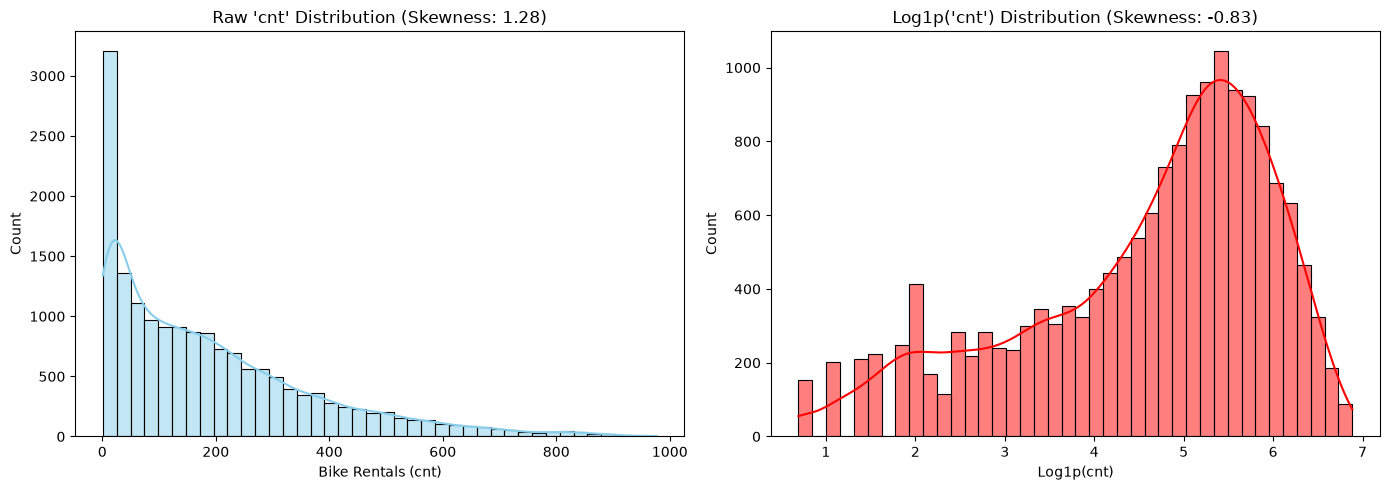

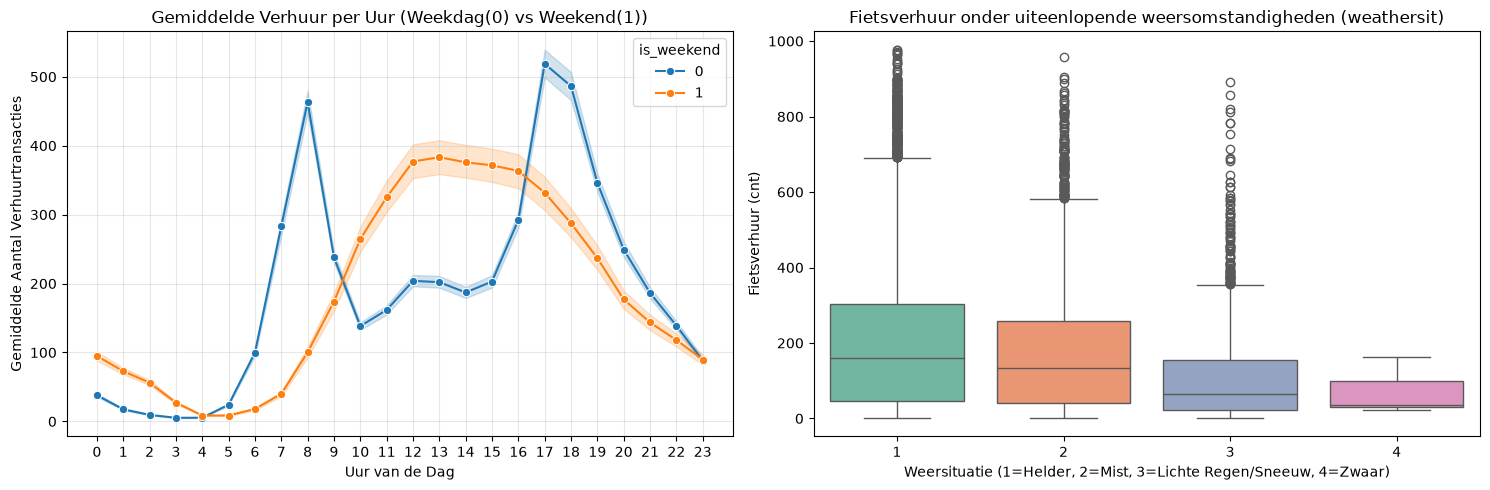

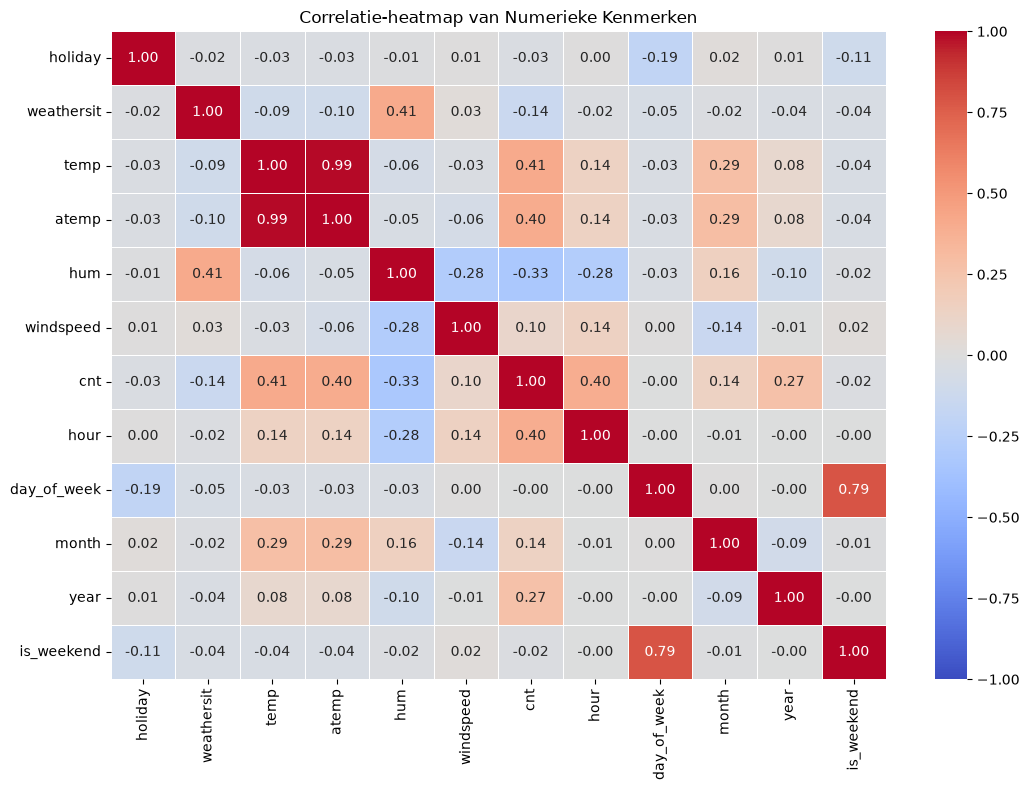

In [48]:
# Initialiseer de feature-engineer en EDA-analyzer
eda = EDAAnalyzer(datetime_col="date_hour", target_col="cnt")
time_eng = TimeFeatureEngineer(datetime_col="date_hour")

# Creeer kalendarkenmerken voor zowel de trainings- als de testset
train_df = time_eng.extract_calendar_features(train_df)
test_df = time_eng.extract_calendar_features(test_df)

# Analyseer de verdeling en de scheefheid van de doelvariabele
eda.plot_target_distribution(train_df)

# Ontdek de spitsuren per uur en de impact van het weer
eda.plot_key_relationships(train_df)

# Controleer correlaties tussen kenmerken (vooral temp vs atemp)
eda.plot_correlation_heatmap(train_df)


### 1.4 **Tijdcontinuiteit en datasplitsing**


In [49]:
# Controleer de opsplitsing in de tijd en de continuiteit van de uurreeks
eda.inspect_time_split(train_df, test_df)
eda.inspect_time_continuity({"Train": train_df, "Test": test_df})


--- TIME SPLIT ---
Train range: 2011-01-01 00:00:00 to 2012-11-30 23:00:00 (n = 16637)
Test range:  2012-12-01 00:00:00 to 2012-12-19 23:00:00 (n = 456)
Aantal testdagen: 19

--- TIME CONTINUITY ---
Train: 16637 rijen, 16800 uurwaarden verwacht, 163 ontbrekende uren, 73 gaten, langste gat 1 days 13:00:00, dubbelen 0
Test: 456 rijen, 456 uurwaarden verwacht, 0 ontbrekende uren, 0 gaten, langste gat 0 days 01:00:00, dubbelen 0



##### **Bevindingen: tijdcontinuiteit en datasplitsing**

+ De **trainset** loopt van 2011-01-01 00:00 tot 2012-11-30 23:00. In dat venster zijn **16.800 uurwaarden** verwacht, maar de dataset bevat **16.637 rijen**. Er ontbreken dus **163 uren**, verdeeld over **73 gaten**; het langste gat is **37 uur** (1 dag en 13 uur).
+ De **testset** is volledig aaneengesloten: 456 van 456 uurwaarden (19 dagen).
+ Er zijn **geen dubbele tijdstippen** in beide datasets.
+ Gevolg voor de analyse: de rolling means, FFT en ACF gaan uit van een aaneengesloten uurreeks. Omdat de ontbrekende uren ongeveer 1% van de reeks vormen, is de vertekening beperkt, maar het blijft een beperking van de analyse. De tijdfeatures (`time_index`, Fourier) worden daarom op basis van de **echte tijdstempels** berekend en niet op basis van rijnummers.


### 1.5 **Belangrijkste bevindingen van de EDA**


##### Lijngrafiek per uur, uitgesplitst naar weekend vs doordeweekse dagen:
##### 1. Spitsuren & de invloed van het weer: Doordeweekse dagen (is_weekend = 0) vertonen duidelijke, bimodale pieken in het woon-werkverkeer om 08:00 uur (ongeveer 460 verhuurtransacties) en tussen 17:00 en 18:00 uur (ongeveer 515 verhuurtransacties).
##### 2. Weekenden (is_weekend = 1): Toont een enkele, vloeiende curve voor vrijetijdsbesteding, met een piek tussen 12:00 en 16:00 uur (~370–380 verhuurgevallen).

##### Weersituatie Boxplot:
##### 3. Weer (weathersit): Het aantal verhuurde fietsen daalt gestaag naarmate het weer verslechtert, van helder (1) tot lichte regen/sneeuw (3), terwijl er bij zware regen/sneeuw (4) bijna geen waarnemingen zijn.

##### Correlatiematrix voor numerieke kenmerken: 
##### 4. Multicollineariteit & belangrijkste voorspellers: 'temp' en 'atemp' vertonen een vrijwel identieke correlatie van 0,99. Het behouden van beide zorgt voor redundantie / 'overfitten' in lineaire modellen; het is daarom raadzaam om te onderzoeken of er een van kunt weglaten.
##### 5. De sterkste lineaire correlaties met 'cnt' zijn temp (0,41), atemp (0,40), hour (0,40), hum (-0,33), year (0,27), weathersit (-0,14) en month (0,14). Merk op dat 'year' een positieve correlatie van 0,27 vertoont; dit betekent dat het totale fietsgebruik tussen 2011 en 2012 aanzienlijk is gegroeid.

##### Histogram van ruwe doelscheefheid tegen de log1p-getransformeerde doelscheefheid:
##### 6. Doelscheefheid: De onbewerkte variabele 'cnt' is sterk rechtsscheef (scheefheid = 1,28), waarbij in de meeste uren minder dan 200 verhuurtransacties plaatsvinden, met een lange staart die doorloopt tot ongeveer 950.
##### 7. Het toepassen van np.log1p(cnt) verlaagt de scheefheid van 1,28 naar -0,83. Dat is een duidelijke verbetering, maar de verdeling blijft linksscheef (|scheefheid| > 0,5); van volledige symmetrie is dus geen sprake. Omdat de modellen vooral baat hebben bij het intomen van de lange rechterstaart, gebruiken we log1p(cnt) als transformatie van de doelvariabele.


## 2. **Data opschonen en voorbereiden**


In [50]:
# Initialiseer de DataPreparer
preparer = DataPreparer(datetime_col="date_hour", target_col="cnt")

# Voer anomaliecontroles uit op zowel de trainings- als de testsets
preparer.check_anomalies(train_df, name="Train")
preparer.check_anomalies(test_df, name="Test")

# Anomalieen opschonen en de redundante variabele "atemp" verwijderen (correlatie 0,99 met "temp")
train_clean = preparer.clean_data(train_df, drop_atemp=True)
test_clean = preparer.clean_data(test_df, drop_atemp=True)


--- ANOMALY & SUMMARY CHECK (Train) ---


,min,50%,mean,max,std
date_hour,2011-01-01 00:00:00,2011-12-18 06:00:00,2011-12-18 02:20:08.294764,2012-11-30 23:00:00,NaN
holiday,0.0,0.0,0.028671,1.0,0.166885
weathersit,1.0,1.0,1.41558,4.0,0.637298
temp,0.02,0.52,0.504745,1.0,0.192369
atemp,0.0,0.5,0.482608,1.0,0.171557
hum,0.0,0.62,0.624756,1.0,0.193227
windspeed,0.0,0.194,0.19031,0.8507,0.121915
cnt,1.0,143.0,190.477009,977.0,182.026755
hour,0.0,12.0,11.547875,23.0,6.914199
day_of_week,0.0,3.0,3.008776,6.0,1.998538


Rows with hum == 0: 22
Rows with windspeed == 0: 2072

--- ANOMALY & SUMMARY CHECK (Test) ---


,min,50%,mean,max,std
date_hour,2012-12-01 00:00:00,2012-12-10 11:30:00,2012-12-10 11:30:00,2012-12-19 23:00:00,NaN
holiday,0.0,0.0,0.0,0.0,0.0
weathersit,1.0,2.0,1.592105,3.0,0.607882
temp,0.16,0.36,0.360132,0.6,0.079432
atemp,0.1818,0.3636,0.363691,0.6212,0.076354
hum,0.33,0.75,0.714868,1.0,0.177732
windspeed,0.0,0.1343,0.157639,0.4925,0.106499
hour,0.0,11.5,11.5,23.0,6.929789
day_of_week,0.0,3.0,2.947368,6.0,2.091709
month,12.0,12.0,12.0,12.0,0.0


Rows with hum == 0: 0
Rows with windspeed == 0: 72



#### **2.1 Onderbouwing van het opschonen**

+ **hum == 0**: 22 rijen in de trainset en 0 in de testset. Een luchtvochtigheid van exact 0% is fysiek onwaarschijnlijk en wijst op een sensorfout. Deze waarden zijn naar `NaN` gezet en lineair geinterpoleerd.
+ **windspeed == 0**: 2.072 rijen in de trainset (12,5%) en 72 in de testset. Dit is geen sensorfout maar windstilte; 0 is een geldige meting. Deze rijen blijven daarom behouden.
+ **atemp**: correleert 0,99 met `temp`. Beide behouden zorgt voor multicollineariteit in lineaire modellen, daarom is `atemp` verwijderd.
+ **Tijdstippen**: geen dubbele tijdstippen, wel ontbrekende uren (zie 1.4). Er is niet geinterpoleerd in de doelvariabele, omdat dat de validatie zou vertekenen. De tijdfeatures worden op basis van de echte tijdstempels berekend, zodat ontbrekende uren geen verschuiving veroorzaken.


## 3. **Time series feature engineering (Opdracht 2)**


In dit deel onderzoeken we de tijdreeksstructuur van de data en vertalen we die naar features:

1. **Trend** - langetermijngroei in de vraag.
2. **Seizoenspatronen met Fourier-analyse** - welke perioden (dag, week, jaar) domineren?
3. **Cycli en autocorrelatie** - hoe sterk hangt de vraag op dit uur samen met eerdere uren?
4. **Overige tijdsgebaseerde features** - spitsuren, nacht, werkdagen en een interactie met temperatuur.

De klasse hieronder bevat zowel de analysemethoden als de feature-constructors. In deel 4 meten we wat de invloed van elke featuregroep op de voorspellingen is.


In [51]:
class TimeSeriesAnalyzerAndEngineer:
    """ Voert tijdreeksdiagnostiek uit (trend, Fourier, ACF/PACF) en bouwt tijdreeksfeatures."""

    def __init__(self, datetime_col: str = "date_hour", target_col: str = "cnt"):
        self.datetime_col = datetime_col
        self.target_col = target_col

    # TRENDS
    def plot_trends(self, df: pd.DataFrame):
        """ Toont de ruwe uurreeks met 7- en 30-daagse voortschrijdende gemiddelden.

        Zo wordt de langetermijntrend zichtbaar.
        """
        ts = df.set_index(self.datetime_col)[self.target_col]
        rolling_7d = ts.rolling(window=24 * 7, min_periods=1).mean()
        rolling_30d = ts.rolling(window=24 * 30, min_periods=1).mean()

        plt.figure(figsize=(15, 5))
        plt.plot(ts.index, ts, alpha=0.2, color="gray", label="Verhuur per Uur (Onbewerkt)")
        plt.plot(
            rolling_7d.index, rolling_7d, color="green", linewidth=1.5, label="7-day Rolling Mean"
        )
        plt.plot(
            rolling_30d.index, rolling_30d, color="r", linewidth=2.5, label="30-day Rolling Mean"
        )
        plt.title("Langetermijntrend & seizoensinvloeden bij fietsverhuur (2011 - 2012)")
        plt.xlabel("Datum")
        plt.ylabel("Verhuur (cnt)")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    def add_trend_features(self, df: pd.DataFrame, start_date: pd.Timestamp) -> pd.DataFrame:
        """ Voegt een continue tijdindex toe (uren sinds de startdatum) als trendfeature."""
        df = df.copy()
        df["time_index"] = (df[self.datetime_col] - start_date).dt.total_seconds() / 3600.0
        return df

    def _detrended_target(self, df: pd.DataFrame) -> np.ndarray:
        """ Haalt de lineaire trend uit de doelvariabele; anders domineert die de FFT en ACF."""
        y = df[self.target_col].to_numpy(dtype=float)
        verstreken = (df[self.datetime_col] - df[self.datetime_col].min()).dt.total_seconds()
        x = verstreken.to_numpy() / 3600.0
        trend = np.polyval(np.polyfit(x, y, 1), x)
        return y - trend

    # FOURIER SEASONALITY
    def plot_fourier_spectrum(self, df: pd.DataFrame, top_n: int = 6) -> pd.DataFrame:
        """ Berekent de FFT op de ont-trende reeks, plot het spectrum en geeft de top terug."""
        signal = self._detrended_target(df)
        power = np.abs(np.fft.rfft(signal))
        freqs = np.fft.rfftfreq(len(signal), d=1.0)  # d = 1 uur

        valid = freqs > 0
        periods = 1.0 / freqs[valid]
        power = power[valid]

        plt.figure(figsize=(14, 5))
        plt.plot(periods, power, color="steelblue", linewidth=1.2)
        plt.xscale("log")

        # Markeer de belangrijkste verwachte cycli
        verwachte_cycli = [
            (12, "12h (dubbel dagpatroon)"),
            (24, "24h (dagelijks)"),
            (168, "168h (wekelijks)"),
            (8760, "8760h (jaarlijks)"),
        ]
        for periode, label in verwachte_cycli:
            plt.axvline(periode, color="r", linestyle="--", alpha=0.8)
            plt.text(
                periode * 1.05,
                power.max() * 0.85,
                label,
                rotation=90,
                verticalalignment="top",
                fontsize=9,
            )

        plt.title("Fourier Power Spectrum van de ont-trende reeks (logaritmische periode-as)")
        plt.xlabel("Periode (uren, log-schaal)")
        plt.ylabel("Fourier-amplitude")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        # Selecteer de sterkste perioden en sla buren binnen 5% over
        top = []
        for idx in np.argsort(power)[::-1]:
            periode = periods[idx]
            if all(abs(periode - gekozen) / gekozen > 0.05 for gekozen in top):
                top.append(periode)
            if len(top) == top_n:
                break
        sterkste_perioden = pd.DataFrame({"periode_uren": top})
        sterkste_perioden["periode_dagen"] = (sterkste_perioden["periode_uren"] / 24).round(1)
        sterkste_perioden["power"] = [
            power[np.argmin(np.abs(periods - p))] for p in sterkste_perioden["periode_uren"]
        ]
        return sterkste_perioden

    def add_fourier_features(
        self, df: pd.DataFrame, harmonics: dict[int, int] | None = None
    ) -> pd.DataFrame:
        """ Voegt sin/cos-paren toe voor elke periode, met n harmonischen per periode."""
        if harmonics is None:
            harmonics = {24: 2, 168: 2, 8760: 1}

        df = df.copy()
        if "time_index" not in df.columns:
            raise ValueError("Run add_trend_features() first so 'time_index' exists.")

        for period, n_harmonics in harmonics.items():
            for k in range(1, n_harmonics + 1):
                angle = 2 * np.pi * k * df["time_index"] / period
                df[f"sin_{period}h_k{k}"] = np.sin(angle)
                df[f"cos_{period}h_k{k}"] = np.cos(angle)
        return df

    # CYCLES & AUTOCORRELATION
    def plot_autocorrelation(self, df: pd.DataFrame, max_lags: int = 168) -> None:
        """ Toont de ACF en PACF van de ont-trende reeks (max_lags = 168 uur = 1 volledige week)."""
        signal = pd.Series(self._detrended_target(df))

        _, axes = plt.subplots(2, 1, figsize=(15, 8))

        plot_acf(signal, lags=max_lags, ax=axes[0], color="steelblue")
        axes[0].set_title(f"ACF van de ont-trende reeks tot {max_lags} uur (1 week)")
        axes[0].set_xlabel("Lag (uren)")

        plot_pacf(signal, lags=72, ax=axes[1], color="seagreen", method="ywm")
        axes[1].set_title("PACF van de ont-trende reeks tot 72 uur (3 dagen)")
        axes[1].set_xlabel("Lag (uren)")

        plt.tight_layout()
        plt.show()

    def acf_at_lags(self, df: pd.DataFrame, lags: tuple[int, ...] = (24, 48, 168)) -> pd.Series:
        """ Geeft de ACF-waarden op specifieke lags terug (voor de interpretatie)."""
        waarden = acf(self._detrended_target(df), nlags=max(lags), fft=True)
        return pd.Series({f"lag_{lag}h": waarden[lag] for lag in lags})

    # OTHER TIME-BASED & INTERACTION FEATURES
    def add_domain_time_features(self, df: pd.DataFrame) -> pd.DataFrame:
        """ Voegt spitsuren, nachtindicator, werkdagindicator en een temperatuurinteractie toe."""
        df = df.copy()

        # Definieer "workingday": geen weekend en geen feestdag
        df["workingday"] = ((df["is_weekend"] == 0) & (df["holiday"] == 0)).astype(int)

        # Ochtendspits (7-9 uur) en avondspits (16-19 uur) op werkdagen
        is_commute_hour = df["hour"].isin([7, 8, 9, 16, 17, 18, 19])
        df["is_rush_hour"] = (is_commute_hour & (df["workingday"] == 1)).astype(int)

        # Nachtindicator (00:00 - 05:00), wanneer de vraag het laagst is
        df["is_night"] = df["hour"].isin([0, 1, 2, 3, 4, 5]).astype(int)

        # Interactie: warm weer stimuleert vrijetijdsfietsen anders op werkdagen dan in het weekend.
        df["temp_x_workingday"] = df["temp"] * df["workingday"]
        return df


### 3.1 **Onderzoek naar trends**


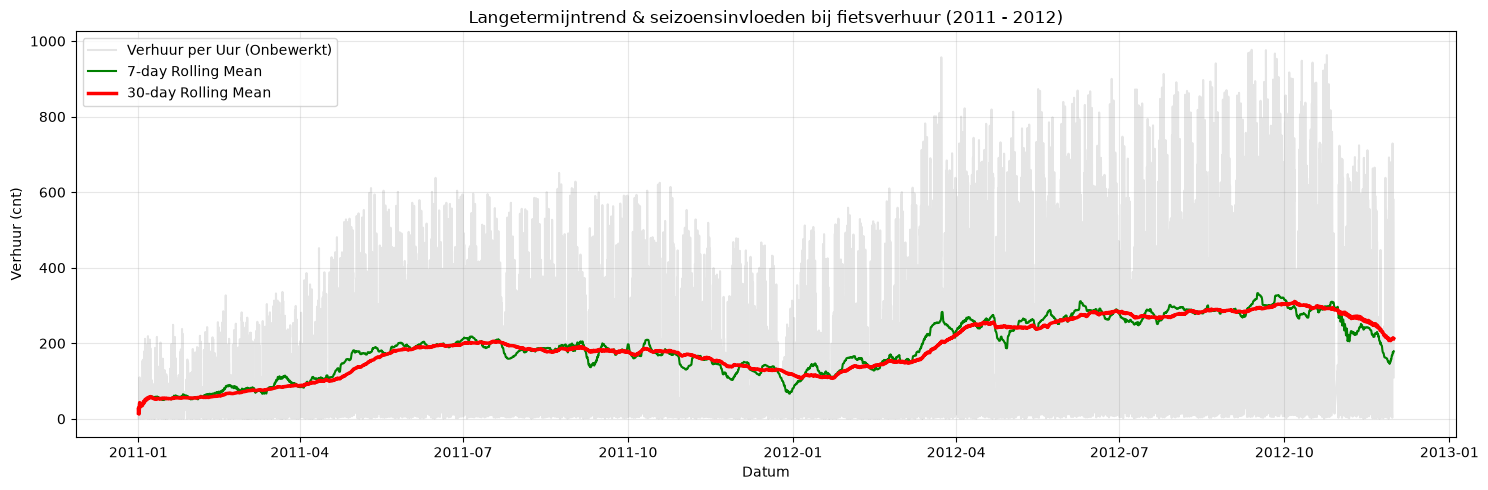

,mean,sum,count
year,,,
2011,146.2,1155780,7904
2012,241.0,1925863,7992


Gemiddeld aantal verhuur per uur (jan-nov): 64.8% groei van 2011 naar 2012
30-daags rollend gemiddelde: min 13 op 2011-01-01, max 311 op 2012-10-06


In [52]:
ts_engineer = TimeSeriesAnalyzerAndEngineer(datetime_col="date_hour", target_col="cnt")

# Trend zichtbaar maken met 7- en 30-daagse voortschrijdende gemiddelden
ts_engineer.plot_trends(train_clean)

# Groei kwantificeren: vergelijk januari t/m november van beide jaren
yearly = (
    train_clean[train_clean["month"] <= 11].groupby("year")["cnt"].agg(["mean", "sum", "count"])
)
display(yearly.round(1))
growth = (yearly.loc[2012, "mean"] / yearly.loc[2011, "mean"] - 1) * 100
print(f"Gemiddeld aantal verhuur per uur (jan-nov): {growth:.1f}% groei van 2011 naar 2012")

rolling_30d_reeks = (
    train_clean.set_index("date_hour")["cnt"].rolling(24 * 30, min_periods=1).mean()
)
print(
    f"30-daags rollend gemiddelde: min {rolling_30d_reeks.min():.0f} "
    f"op {rolling_30d_reeks.idxmin():%Y-%m-%d}, "
    f"max {rolling_30d_reeks.max():.0f} op {rolling_30d_reeks.idxmax():%Y-%m-%d}"
)


##### **Bevindingen: trend**

+ De vraag groeit structureel: het gemiddelde aantal verhuur per uur in januari t/m november stijgt van **146,2 in 2011** naar **241,0 in 2012**, een groei van **64,8%**.
+ Het 30-daagse voortschrijdende gemiddelde loopt op van **13** (1 januari 2011) naar **311** (6 oktober 2012).
+ De trend is niet lineair: in de winter van 2011/2012 daalt het 30-daagse gemiddelde (seizoensdal), waarna het in het voorjaar van 2012 opnieuw sterk stijgt. Een simpele lineaire `time_index` is daarom een benadering; in deel 4 blijkt hij nauwelijks iets toe te voegen bovenop de kalenderfeatures.


### 3.2 **Onderzoek naar seizoenspatronen met Fourier-analyse**


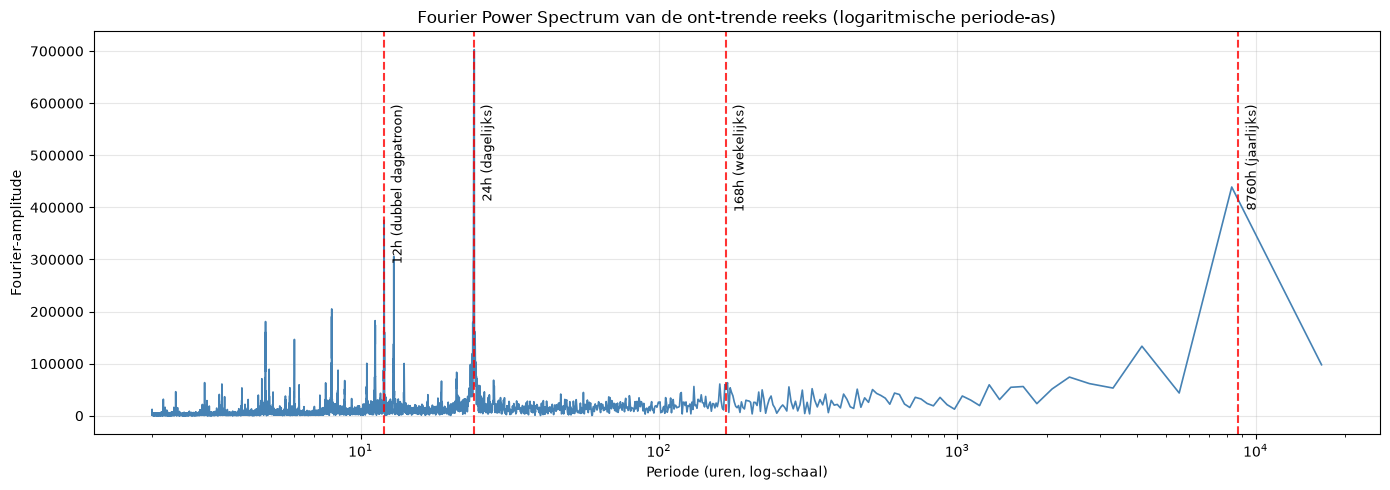

,periode_uren,periode_dagen,power
0,24.0,1.0,702786.9
1,8318.5,346.6,439107.2
2,12.0,0.5,375193.2
3,12.9,0.5,305708.3
4,8.0,0.3,205041.0
5,11.2,0.5,182599.1


In [53]:
top_periods = ts_engineer.plot_fourier_spectrum(train_clean, top_n=6)
display(top_periods.round(1))


##### **Bevindingen: Fourier-analyse**

+ Het spectrum wordt gedomineerd door de **dagcyclus**: de sterkste piek ligt op **24,0 uur** (power 702.787). De naastgelegen bins (23,97 uur, power 699.631) horen bij dezelfde piek en ontstaan door spectrale lekkage.
+ De **halfdaagse harmonischen** zijn duidelijk aanwezig: **12,0 uur** (375.193) en **12,9 uur** (305.708), plus de derde harmonische op **8,0 uur** (205.041). Dit past bij het dubbele dagpatroon met een ochtend- en een avondpiek.
+ Op de lange termijn is de **jaarcyclus** de sterkste component: **8.318,5 uur ≈ 346,6 dagen** (power 439.107). Dat de periode iets korter is dan 365 dagen komt doordat de reeks maar twee jaar beslaat en de trend niet perfect lineair is.
+ De **weekcyclus (168 uur)** is in dit spectrum zwak (power ongeveer 63.500, een kleine lokale piek rond 169,8 uur). Dat komt doordat de dagelijkse schommeling veel groter is dan het verschil tussen weekdagen en weekend. De autocorrelatie in 3.3 laat wel een duidelijke piek op 168 uur zien, daarom wordt de weekperiode als feature meegenomen.


### 3.3 **Onderzoek naar cycli en autocorrelatie**


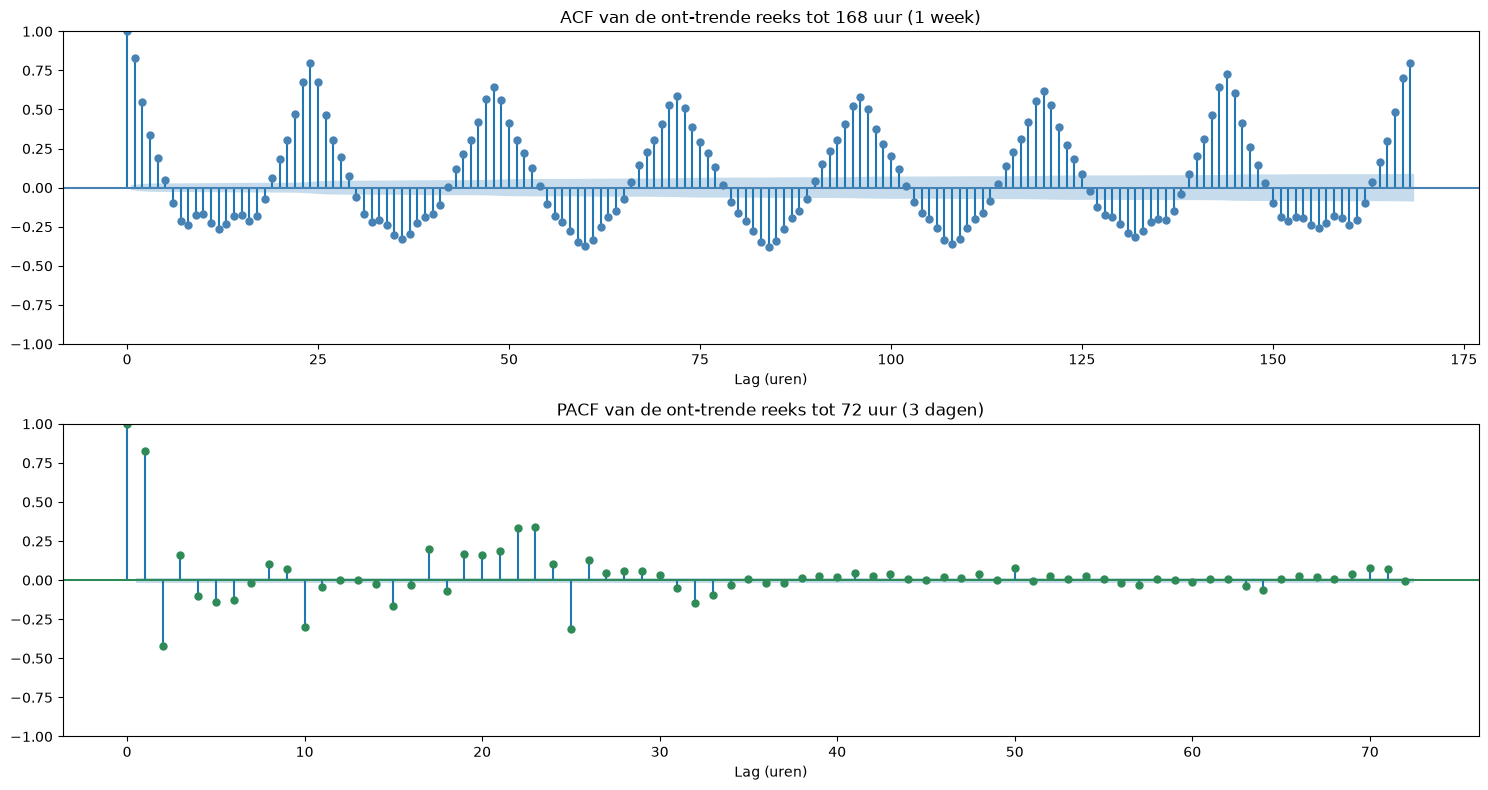

lag_24h     0.795
lag_48h     0.644
lag_168h    0.799
dtype: float64

In [54]:
ts_engineer.plot_autocorrelation(train_clean, max_lags=168)
display(ts_engineer.acf_at_lags(train_clean, lags=(24, 48, 168)).round(3))


##### **Bevindingen: cycli en autocorrelatie**

+ Kortetermijn: de ACF op lag 1 is **0,83**. De vraag van het vorige uur is dus sterk voorspellend.
+ **Dagcyclus:** er is een duidelijke piek op lag 24 (**0,80**), met lagere waarden direct ervoor en erna (lag 23: 0,68; lag 25: 0,67). Op lag 48 is de piek **0,64**; de correlatie neemt per dag af.
+ **Weekcyclus:** de piek op lag 168 (**0,80**) is zelfs iets hoger dan die op lag 24 en is een duidelijke lokale piek (lag 167: 0,70; lag 169: 0,65). Er is dus een echt weekritme, ook al is dat in het Fourier-spectrum minder zichtbaar.
+ De **negatieve waarde op lag 12 (-0,26)** bevestigt het dubbele dagpatroon: twaalf uur na een spits zit je in het dal tussen de pieken.
+ De PACF laat zien dat de directe voorspelkracht vooral in lag 1 en 2 zit. Daarna zijn er kleinere, significante pieken rond de dagcyclus (lag 23-25).


### 3.4 **Overige tijdsgebaseerde features en toepassing**


In [55]:
# Pas de geconstrueerde kenmerken toe op zowel de trainings- als de testset
train_start = train_clean["date_hour"].min()

train_fe = ts_engineer.add_trend_features(train_clean, start_date=train_start)
test_fe = ts_engineer.add_trend_features(test_clean, start_date=train_start)

train_fe = ts_engineer.add_fourier_features(train_fe, harmonics={24: 2, 168: 2, 8760: 1})
test_fe = ts_engineer.add_fourier_features(test_fe, harmonics={24: 2, 168: 2, 8760: 1})

train_fe = ts_engineer.add_domain_time_features(train_fe)
test_fe = ts_engineer.add_domain_time_features(test_fe)

print("New shape of train_fe:", train_fe.shape)
print("New shape of test_fe:", test_fe.shape)
feature_kolommen = "^(time_index|sin_|cos_|workingday|is_rush_hour|is_night|temp_x_workingday)"
display(train_fe.filter(regex=feature_kolommen).head())


New shape of train_fe: (16637, 27)
New shape of test_fe: (456, 26)


,time_index,sin_24h_k1,cos_24h_k1,sin_24h_k2,cos_24h_k2,sin_168h_k1,cos_168h_k1,sin_168h_k2,cos_168h_k2,sin_8760h_k1,cos_8760h_k1,workingday,is_rush_hour,is_night,temp_x_workingday
0,0.0,0.000000,1.000000,0.000000,1.000000e+00,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0,0,1,0.0
1,1.0,0.258819,0.965926,0.500000,8.660254e-01,0.037391,0.999301,0.074730,0.997204,0.000717,1.000000,0,0,1,0.0
2,2.0,0.500000,0.866025,0.866025,5.000000e-01,0.074730,0.997204,0.149042,0.988831,0.001435,0.999999,0,0,1,0.0
3,3.0,0.707107,0.707107,1.000000,6.123234e-17,0.111964,0.993712,0.222521,0.974928,0.002152,0.999998,0,0,1,0.0
4,4.0,0.866025,0.500000,0.866025,-5.000000e-01,0.149042,0.988831,0.294755,0.955573,0.002869,0.999996,0,0,1,0.0


Na het toevoegen van de features heeft `train_fe` **27 kolommen** (25 features plus `date_hour` en `cnt`) en `test_fe` **26 kolommen**.

Gekozen Fourier-harmonischen, op basis van het spectrum in 3.2:

+ **24 uur - 2 harmonischen**: de dagcyclus plus de 12-uurs harmonische, samen goed voor de dubbele dagpiek.
+ **168 uur - 2 harmonischen**: het weekritme uit de ACF; twee harmonischen geven de weekvorm iets meer vrijheid.
+ **8760 uur - 1 harmonische**: de jaarcyclus. Meer harmonischen hebben weinig zin, omdat de reeks maar twee jaar beslaat en de trend het grootste deel van de langzame variatie al opvangt.

Daarnaast zijn `workingday`, `is_rush_hour`, `is_night` en `temp_x_workingday` toegevoegd. `time_index` en de Fourierfeatures worden voor de testset met **dezelfde startdatum** berekend, zodat de tijdas naadloos aansluit.


## 4. **Invloed van de features op de voorspellingen**


Opdracht 2 vraagt niet alleen om features, maar ook om te onderzoeken wat hun invloed is op de voorspellingen. We doen daarom een **ablatietest**: dezelfde modellen worden getraind op een cumulatief groeiende featureset en de fout wordt op chronologische wijze vergeleken.

+ **Featuresets**: (0) basis weer + feestdag -> (1) + kalenderfeatures -> (2) + trend -> (3) + Fourier -> (4) + domeinfeatures.
+ **Modellen**: Ridge (lineair, met L2-regularisatie) en Random Forest (niet-lineair ensemble), zodat de conclusie niet van een enkel model afhangt.
+ **Validatie**: `TimeSeriesSplit` met 4 chronologische folds van 30 dagen (geen shuffle, dus geen toekomstinformatie) en daarnaast een hold-out met de laatste 19 dagen, dezelfde horizon als de Kaggle-testset.
+ **Doelvariabele**: `log1p(cnt)`; voorspellingen worden met `expm1` teruggetransformeerd.
+ **Metrieken**: MAE en RMSE in fietsen per uur, en RMSLE (relatief, sluit aan bij de competitie).


In [56]:
# Chronologische splitsing: de laatste 19 dagen bootsen het testblok van de Kaggle-competitie na
X_train, X_val, y_train, y_val = preparer.create_time_validation_split(
    train_fe, val_days=19, use_log_target=True
)

fourier_cols = [col for col in train_fe.columns if col.startswith(("sin_", "cos_"))]

# Cumulatieve featuresets: elke stap voegt een groep tijdreeksfeatures toe
FEATURE_GROUPS = [
    ("0. Basis (weer + feestdag)", ["holiday", "weathersit", "temp", "hum", "windspeed"]),
    ("1. + kalenderfeatures", ["hour", "day_of_week", "month", "year", "is_weekend"]),
    ("2. + trend (time_index)", ["time_index"]),
    ("3. + Fourierfeatures", fourier_cols),
    ("4. + domeinfeatures", ["workingday", "is_rush_hour", "is_night", "temp_x_workingday"]),
]

feature_configs = {}
cumulatief = []
for groepsnaam, groep_kolommen in FEATURE_GROUPS:
    cumulatief = cumulatief + groep_kolommen
    feature_configs[groepsnaam] = list(cumulatief)


def maak_model(naam: str):
    """ Geeft per modelnaam een nieuw, ongetraind model terug."""
    if naam == "Ridge":
        return Ridge(alpha=1.0)
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1)


def rmsle(y_true, y_pred) -> float:
    """ Root Mean Squared Logarithmic Error tussen werkelijke en voorspelde waarden."""
    return float(np.sqrt(np.mean((np.log1p(y_true) - np.log1p(y_pred)) ** 2)))


def fit_en_score(
    naam: str,
    kolommen: list[str],
    train: tuple[pd.DataFrame, pd.Series],
    valid: tuple[pd.DataFrame, pd.Series],
) -> dict:
    """ Traint het model en scoort op de validatieset, teruggerekend naar fietsen per uur."""
    X_tr, y_tr = train
    X_te, y_te = valid

    # De preprocessor wordt per featureset op de trainingsfold gebouwd, zodat er geen
    # kolominformatie of schaalstatistiek uit de validatieset weglekt.
    pijplijn = Pipeline(
        [
            ("prep", preparer.build_preprocessor(X_tr[kolommen], scale_numeric=naam == "Ridge")),
            ("model", maak_model(naam)),
        ]
    )
    pijplijn.fit(X_tr[kolommen], y_tr)
    voorspelling = np.clip(np.expm1(pijplijn.predict(X_te[kolommen])), 0, None)
    werkelijk = np.expm1(y_te)
    return {
        "MAE": mean_absolute_error(werkelijk, voorspelling),
        "RMSE": np.sqrt(mean_squared_error(werkelijk, voorspelling)),
        "RMSLE": rmsle(werkelijk, voorspelling),
    }


# Time-series cross-validatie: 4 chronologische folds van 30 dagen
tscv = TimeSeriesSplit(n_splits=4, test_size=24 * 30)

cv_resultaten = []
for modelnaam in ("Ridge", "Random Forest"):
    for config, groep_kolommen in feature_configs.items():
        scores = {"MAE": [], "RMSE": [], "RMSLE": []}
        for train_idx, val_idx in tscv.split(X_train):
            fold = fit_en_score(
                modelnaam,
                groep_kolommen,
                (X_train.iloc[train_idx], y_train.iloc[train_idx]),
                (X_train.iloc[val_idx], y_train.iloc[val_idx]),
            )
            for metric, waarde in fold.items():
                scores[metric].append(waarde)
        cv_resultaten.append(
            {
                "model": modelnaam,
                "features": config,
                "n_features": len(groep_kolommen),
                "MAE": np.mean(scores["MAE"]),
                "MAE_std": np.std(scores["MAE"]),
                "RMSE": np.mean(scores["RMSE"]),
                "RMSLE": np.mean(scores["RMSLE"]),
            }
        )

cv_resultaten = pd.DataFrame(cv_resultaten).sort_values(["model", "MAE"]).reset_index(drop=True)
print("Time-series cross-validatie (gemiddelde over 4 folds van 30 dagen)")
display(cv_resultaten.round(2))

# Hold-out: de laatste 19 dagen, dezelfde horizon als de Kaggle-testset
holdout_resultaten = []
for modelnaam in ("Ridge", "Random Forest"):
    for config, groep_kolommen in feature_configs.items():
        score = fit_en_score(modelnaam, groep_kolommen, (X_train, y_train), (X_val, y_val))
        holdout_resultaten.append(
            {"model": modelnaam, "features": config, "n_features": len(groep_kolommen), **score}
        )

holdout_resultaten = (
    pd.DataFrame(holdout_resultaten).sort_values(["model", "MAE"]).reset_index(drop=True)
)
print("Hold-out: laatste 19 dagen")
display(holdout_resultaten.round(2))


Train split: 2011-01-01 00:00:00 to 2012-11-11 23:00:00 (n=16182)
Val split:   2012-11-12 00:00:00 to 2012-11-30 23:00:00 (n=455)
Time-series cross-validatie (gemiddelde over 4 folds van 30 dagen)


,model,features,n_features,MAE,MAE_std,RMSE,RMSLE
0,Random Forest,4. + domeinfeatures,25,42.11,4.72,68.10,0.31
1,Random Forest,3. + Fourierfeatures,21,43.13,3.70,69.19,0.31
2,Random Forest,2. + trend (time_index),11,43.72,2.72,69.49,0.31
3,Random Forest,1. + kalenderfeatures,10,46.67,5.43,73.57,0.32
4,Random Forest,0. Basis (weer + feestdag),5,177.23,12.87,246.45,1.27
5,Ridge,4. + domeinfeatures,25,90.79,4.49,132.62,0.55
6,Ridge,3. + Fourierfeatures,21,113.35,3.26,165.13,0.65
7,Ridge,1. + kalenderfeatures,10,148.04,6.37,211.39,0.97
8,Ridge,2. + trend (time_index),11,148.17,6.19,211.55,0.97
9,Ridge,0. Basis (weer + feestdag),5,181.21,18.30,253.28,1.20


Hold-out: laatste 19 dagen


,model,features,n_features,MAE,RMSE,RMSLE
0,Random Forest,3. + Fourierfeatures,21,40.10,72.00,0.42
1,Random Forest,4. + domeinfeatures,25,40.83,73.73,0.42
2,Random Forest,2. + trend (time_index),11,41.84,76.89,0.46
3,Random Forest,1. + kalenderfeatures,10,41.93,76.19,0.42
4,Random Forest,0. Basis (weer + feestdag),5,135.57,195.18,1.42
5,Ridge,4. + domeinfeatures,25,74.93,120.28,0.63
6,Ridge,3. + Fourierfeatures,21,90.37,137.44,0.72
7,Ridge,1. + kalenderfeatures,10,117.40,174.65,1.08
8,Ridge,2. + trend (time_index),11,117.40,174.66,1.08
9,Ridge,0. Basis (weer + feestdag),5,145.28,207.08,1.37


##### **Bevindingen: invloed van de features**

+ **Tijdreeksfeatures verkleinen de fout sterk.** Zonder tijdsfeatures voorspelt Random Forest met MAE **177,2** (RMSLE 1,27); met alle features is dat **42,1** (RMSLE 0,31), een foutreductie van **76%**. Bij Ridge gaat de MAE van **181,2** naar **90,8** (RMSLE 1,20 -> 0,55), een reductie van **50%**.
+ **Kalenderfeatures** (uur, dag van de week, maand, jaar) leveren de grootste sprong op: Random Forest 177,2 -> 46,7 en Ridge 181,2 -> 148,0.
+ **Fourierfeatures** voegen vooral voor het lineaire model veel toe: Ridge 148,0 -> 113,4 (**-23%**); Random Forest 46,7 -> 43,1 (-8%).
+ **Trend (`time_index`)** voegt weinig extra toe zodra `year` al in de features zit: Ridge 148,0 -> 148,2 (geen verbetering) en Random Forest 46,7 -> 43,7. Dat is logisch: `year` vangt de niveauverschuiving tussen 2011 en 2012 al op, en een boommodel kan `time_index` niet voorbij de hoogste waarde uit de training extrapoleren. Voor de testset (december 2012) is dat laatste een echt bezwaar.
+ **Domeinfeatures** (spits, nacht, werkdag, temperatuurinteractie) geven nog een kleine winst: Ridge 113,4 -> 90,8 (**-20%**), Random Forest 43,1 -> 42,1 (-2%).
+ Op de **hold-out van 19 dagen** is het beeld consistent: Random Forest met Fourierfeatures haalt MAE **40,1** en RMSLE **0,42**; met alle features is dat 40,8. Het verschil tussen beide is klein, dus de domeinfeatures voegen op deze korte horizon weinig toe.
+ Het **Random Forest** presteert duidelijk beter dan Ridge (MAE 42,1 versus 90,8 in de cross-validatie). Dat is een eerste indicatie dat een niet-lineair ensemble de beste keuze is; de definitieve modelkeuze hoort bij Opdracht 3.


## 5. **Submissions voor de Kaggle-competitie**

Voor de inzending maakt elk model één submissionbestand. Per model kiezen we de featureset die op de hold-out van 19 dagen de laagste RMSE scoorde en daarna trainen we dat model opnieuw op **alle** beschikbare trainingsuren, zodat de voorspelling voor december 2012 op zoveel mogelijk historie rust. De voorspellingen gaan terug uit de log-ruimte, worden afgekapt op 0 en afgerond op hele verhuurtransacties.


In [57]:
# Maak per model een submission met de featureset met de laagste RMSE op de hold-out
from pathlib import Path

submission_folder = Path("submissions")
submission_folder.mkdir(exist_ok=True)

beste_per_model = holdout_resultaten.loc[holdout_resultaten.groupby("model")["RMSE"].idxmin()]
display(beste_per_model.round(2))

submission_overzicht = []
for _, rij in beste_per_model.iterrows():
    modelnaam, config = rij["model"], rij["features"]
    kolommen = feature_configs[config]

    # Zelfde pijplijn als in de evaluatie, nu gehertraind op alle trainingsuren
    prep = preparer.build_preprocessor(train_fe[kolommen], scale_numeric=modelnaam == "Ridge")
    pijplijn = Pipeline([("prep", prep), ("model", maak_model(modelnaam))])
    pijplijn.fit(train_fe[kolommen], np.log1p(train_fe["cnt"]))
    voorspelling = np.clip(np.expm1(pijplijn.predict(test_fe[kolommen])), 0, None)

    submission = pd.DataFrame(
        {
            "date_hour": test_fe["date_hour"].dt.strftime("%Y-%m-%d %H:%M:%S"),
            "cnt": np.rint(voorspelling).astype(int),
        }
    )
    bestand = submission_folder / f"submission_{modelnaam.lower().replace(' ', '_')}.csv"
    submission.to_csv(bestand, index=False)

    submission_overzicht.append(
        {
            "model": modelnaam,
            "features": config,
            "bestand": bestand.name,
            "RMSE_holdout": rij["RMSE"],
            "RMSLE_holdout": rij["RMSLE"],
            "gemiddelde_voorspelling": submission["cnt"].mean(),
        }
    )

submission_overzicht = pd.DataFrame(submission_overzicht)
display(submission_overzicht.round(2))

# Controleer dat elk bestand exact dezelfde rijen en volgorde heeft als sample_submission.csv
voorbeeld = pd.read_csv("sample_submission.csv")
for bestand in sorted(submission_folder.glob("submission_*.csv")):
    controle = pd.read_csv(bestand)
    assert controle.columns.tolist() == voorbeeld.columns.tolist(), bestand.name
    assert controle["date_hour"].tolist() == voorbeeld["date_hour"].tolist(), bestand.name
    assert (controle["cnt"] >= 0).all(), bestand.name
    print(f"{bestand.name}: {len(controle)} rijen, gemiddelde voorspelling {controle['cnt'].mean():.1f}")


,model,features,n_features,MAE,RMSE,RMSLE
0,Random Forest,3. + Fourierfeatures,21,40.10,72.00,0.42
5,Ridge,4. + domeinfeatures,25,74.93,120.28,0.63


,model,features,bestand,RMSE_holdout,RMSLE_holdout,gemiddelde_voorspelling
0,Random Forest,3. + Fourierfeatures,submission_random_forest.csv,72.00,0.42,179.87
1,Ridge,4. + domeinfeatures,submission_ridge.csv,120.28,0.63,176.06


submission_random_forest.csv: 456 rijen, gemiddelde voorspelling 179.9
submission_ridge.csv: 456 rijen, gemiddelde voorspelling 176.1


## 6. **Conclusie Opdracht 1 en 2**


**EDA (Opdracht 1)**

+ De vraag kent twee sterke patronen: een **dagcyclus** met een dubbele piek op werkdagen (08:00 en 17:00) en een vlakkere piek in het weekend, en een **jaarcyclus** met een piek in het late voorjaar en de zomer.
+ **Weer** hangt samen met de vraag (temp +0,41, hum -0,33) en bij slechter weer wordt er minder verhuurd; `weathersit` 4 komt met 3 rijen nauwelijks voor.
+ De data is schoon op missende waarden, maar bevat wel **163 ontbrekende uren** en enkele onmogelijke `hum`-waarden (22 rijen); `windspeed == 0` is een geldige meting en blijft staan. `atemp` is verwijderd wegens multicollineariteit met `temp`.
+ De doelvariabele is sterk rechtsscheef (1,28); `log1p` verlaagt dat naar -0,83 en is als transformatie gebruikt.

**Feature engineering (Opdracht 2)**

+ **Trend:** de vraag groeit in dezelfde maanden met **64,8%** van 2011 naar 2012.
+ **Fourier:** de dagcyclus (24 uur) en zijn harmonischen (12 en 8 uur) domineren, gevolgd door de jaarcyclus (ongeveer 8.318 uur). Het weekritme is in het spectrum zwak, maar duidelijk zichtbaar in de ACF (piek op 168 uur).
+ **Autocorrelatie:** de ACF-pieken op 24 en 168 uur (beide ongeveer 0,80) bevestigen de dag- en weekcyclus; lag 1 correleert 0,83.
+ **Invloed op de voorspellingen:** met tijdreeksfeatures daalt de MAE van Random Forest van **177,2** naar **42,1** (-76%) en van Ridge van **181,2** naar **90,8** (-50%). De kalenderfeatures leveren de grootste winst, Fourier voegt vooral voor het lineaire model veel toe, en de domeinfeatures geven een kleine extra verbetering.

Deze uitkomsten vormen de basis voor Opdracht 3 (modelleren): de beste resultaten worden behaald met een niet-lineair ensemble in combinatie met de kalender- en Fourierfeatures; de domeinfeatures voegen daar nog een kleine verbetering aan toe.
